# E0.3a — Causal Bollinger Walk Audit

**Objective:** Explain *why* the frozen E0.2 state machine enters/exits a walk, without changing state labels or tuning thresholds. This is **not yet predictive accuracy testing**. Use **full-year 2025** inputs; November is only a debugging view.

The 5-minute OHLCV input must have UTC **open-time** timestamps and columns `open high low close volume`. Include pre-2025 history for rolling warmup. All state decisions are labeled at completed candle **close** times. ``candidate_since`` is explanatory and never an early confirmed signal.

## 1. Load source data (replace this cell only)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from walk_states import bollinger_from_5m, detect_walk_states
from e03_analysis import (align_to_5m, occupancy, next_walk_probabilities,
                          cross_overlap, conditional_lift, plot_pair)

import requests
from pathlib import Path
import json

START, END = "2025-01-01", "2026-01-01"
TIMEFRAMES = {"4H":"4h", "1H":"1h", "15m":"15min", "5m":"5min"}
PARAMS = dict(near=0.15, confirm_bars=3, exit_bars=2, slope_bars=3)

NOV_START = "2025-11-13"
NOV_END = "2025-11-23"

CONFIGS = {"1D":"1D", "1H":"1h", "15m":"15min", "5m":"5min"}
WINDOW = 20
NEAR = 0.15
CONFIRM_BARS = 3
EXIT_BARS = 2
SLOPE_BARS = 3

REPO = Path("/media/ata/Data/personal/binbot")
DATA_DIR = REPO / "research" / "sentiment_price" / "data"
CACHE_DIR = DATA_DIR / "btcusdt_5m_batches"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Warm-up before 2025 and a buffer for forward-return labels.
START = pd.Timestamp("2024-12-30", tz="UTC")
END = pd.Timestamp("2026-01-02", tz="UTC")  # exclusive

STEP_MS = 5 * 60 * 1000
START_MS = int(START.timestamp() * 1000)
END_MS = int(END.timestamp() * 1000)

print("Expected candles:", (END_MS - START_MS) // STEP_MS)

# Paste the verified 5m OHLCV loader from 02_price_features.ipynb or E03 here.
# TODO: paste verified 5-minute data loading code from 02_price_features.ipynb
all_candles = []
cursor = START_MS

with requests.Session() as session:
    while cursor < END_MS:
        batch_end = min(cursor + 1000 * STEP_MS, END_MS)
        cache_file = CACHE_DIR / f"{cursor}_{batch_end}.json"

        if cache_file.exists():
            batch = json.loads(cache_file.read_text())
        else:
            response = session.get(
                "https://api.binance.com/api/v3/klines",
                params={
                    "symbol": "BTCUSDT",
                    "interval": "5m",
                    "timeZone": "0",
                    "startTime": cursor,
                    "endTime": batch_end - 1,
                    "limit": 1000,
                },
                timeout=30,
            )
            response.raise_for_status()
            batch = response.json()

        if not isinstance(batch, list) or not batch:
            raise ValueError(f"Unexpected response at {cursor}: {batch}")

        # Require every expected candle; do not silently fill gaps.
        expected_opens = list(range(cursor, batch_end, STEP_MS))
        actual_opens = [int(row[0]) for row in batch]

        if actual_opens != expected_opens:
            raise ValueError(
                f"Missing, duplicate or unexpected candles in batch {cursor}"
            )

        if not cache_file.exists():
            temporary = cache_file.with_suffix(".tmp")
            temporary.write_text(json.dumps(batch))
            temporary.replace(cache_file)
            time.sleep(0.2)

        all_candles.extend(batch)
        cursor = batch_end

        print(
            f"\rLoaded {len(all_candles):,} candles",
            end="",
            flush=True,
        )

print("\nDownload/cache loading complete.")
columns = [
    "open_time", "open", "high", "low", "close", "volume",
    "close_time", "quote_volume", "trade_count",
    "taker_buy_volume", "taker_buy_quote_volume", "ignore",
]

bars = pd.DataFrame(all_candles, columns=columns)

bars["open_time"] = pd.to_datetime(bars["open_time"], unit="ms", utc=True)
bars["close_time"] = pd.to_datetime(bars["close_time"], unit="ms", utc=True)

numeric = [
    "open", "high", "low", "close", "volume", "quote_volume",
    "trade_count", "taker_buy_volume", "taker_buy_quote_volume",
]
bars[numeric] = bars[numeric].apply(pd.to_numeric, errors="raise")
bars = bars.set_index("open_time").sort_index()

expected_index = pd.date_range(
    START, END - pd.Timedelta(minutes=5), freq="5min"
)

assert bars.index.is_unique
assert bars.index.equals(expected_index), "Unexpected candle coverage"
assert bars[numeric].notna().all().all()
assert (bars[["open", "high", "low", "close"]] > 0).all().all()
assert (bars["low"] <= bars[["open", "close"]].min(axis=1)).all()
assert (bars["high"] >= bars[["open", "close"]].max(axis=1)).all()
assert (bars["volume"] >= 0).all()
assert "bars" in globals(), "Load your existing 5m OHLCV dataframe as bars first"
assert "bars" in globals(), "First load your verified 5-minute OHLCV dataframe as `bars`."
assert {"open","high","low","close","volume"}.issubset(bars.columns)
print('Rows:',len(bars),'Range:',bars.index.min(),bars.index.max())

Expected candles: 105984
Loaded 105,984 candles
Download/cache loading complete.
Rows: 105984 Range: 2024-12-30 00:00:00+00:00 2026-01-01 23:55:00+00:00


## 2. Frozen detector and parameters

In [2]:
import pandas as pd
from walk_states import bollinger_from_5m
from e03a_trace import audit_walk_states, trace_summary

START, END = '2025-01-01', '2026-01-01'
CONFIG = dict(near=0.15, confirm_bars=3, exit_bars=2, slope_bars=3)
TF = {'4H':'4h','1H':'1h','15m':'15min','5m':'5min'}
print(CONFIG)

{'near': 0.15, 'confirm_bars': 3, 'exit_bars': 2, 'slope_bars': 3}


## 3. Recompute independently and assert exact state/transition parity

In [3]:
runs = {}
for label, step in TF.items():
    bb = bollinger_from_5m(bars, START, END, resolution=step, window=20, num_std=2)
    states, transitions, trace, confirmations = audit_walk_states(bb, **CONFIG)
    runs[label] = dict(bb=bb, states=states, transitions=transitions,
                       trace=trace, confirmations=confirmations)
    print(label, 'PASS', len(states), 'candles', len(confirmations), 'confirmations')

4H PASS 2190 candles 75 confirmations
1H PASS 8760 candles 326 confirmations
15m PASS 35040 candles 1252 confirmations
5m PASS 105120 candles 4040 confirmations


## 4. Full-year diagnostic summary

In [4]:
for label, r in runs.items():
    print('\n',label)
    display(trace_summary(r['trace'],r['confirmations']))
    display(r['transitions'].groupby(['from_state','to_state','reason'],dropna=False).size().rename('count').to_frame())


 4H


,value
valid_candles,2183.0
invalid_candles,7.0
lower_qualifying_candles,265.0
upper_qualifying_candles,290.0
confirmed_walks,75.0
distance_exits,75.0
gap_exits,0.0
median_confirmation_lag_hours,8.0


count
from_state to_state   reason              
LOWER_WALK NEUTRAL    DISTANCE_EXIT     39
NEUTRAL    LOWER_WALK CONFIRMED         39
           UPPER_WALK CONFIRMED         36
UPPER_WALK NEUTRAL    DISTANCE_EXIT     36


 1H


,value
valid_candles,8760.0
invalid_candles,0.0
lower_qualifying_candles,1203.0
upper_qualifying_candles,1247.0
confirmed_walks,326.0
distance_exits,326.0
gap_exits,0.0
median_confirmation_lag_hours,2.0


...

,value
valid_candles,35040.0
invalid_candles,0.0
lower_qualifying_candles,4977.0
upper_qualifying_candles,5035.0
confirmed_walks,1252.0
distance_exits,1252.0
gap_exits,0.0
median_confirmation_lag_hours,0.5


count
from_state to_state   reason              
LOWER_WALK NEUTRAL    DISTANCE_EXIT    612
NEUTRAL    LOWER_WALK CONFIRMED        612
           UPPER_WALK CONFIRMED        640
UPPER_WALK NEUTRAL    DISTANCE_EXIT    640


 5m


,value
valid_candles,105120.000000
invalid_candles,0.000000
lower_qualifying_candles,15510.000000
upper_qualifying_candles,15070.000000
confirmed_walks,4040.000000
distance_exits,4040.000000
gap_exits,0.000000
median_confirmation_lag_hours,0.166667


count
from_state to_state   reason              
LOWER_WALK NEUTRAL    DISTANCE_EXIT   2002
NEUTRAL    LOWER_WALK CONFIRMED       2002
           UPPER_WALK CONFIRMED       2038
UPPER_WALK NEUTRAL    DISTANCE_EXIT   2038

## 5. Inspect candidate qualification, confirmation, exit counter and slope

In [5]:
label='1H'
S='2025-11-22 18:00'; E='2025-11-23 08:00'
r = runs[label]
cols=['pct_b','lower_slope','upper_slope','state']
a=r['states'].loc[S:E,cols].join(r['trace'].loc[S:E,[
    'near_lower','near_upper','lower_slope_ok','upper_slope_ok',
    'qualify_lower','qualify_upper','proposed',
    'candidate_streak','exit_streak','decision','candidate_since']])
display(a)

,pct_b,lower_slope,upper_slope,state,near_lower,near_upper,lower_slope_ok,upper_slope_ok,qualify_lower,qualify_upper,proposed,candidate_streak,exit_streak,decision,candidate_since
2025-11-22 18:00:00+00:00,0.611936,48.100857,-91.077857,NEUTRAL,False,False,False,False,False,False,NONE,0,0,NONE,NaT
2025-11-22 19:00:00+00:00,0.666658,52.462583,-65.373583,NEUTRAL,False,False,False,False,False,False,NONE,0,0,NONE,NaT
2025-11-22 20:00:00+00:00,0.665533,94.209261,-171.433261,NEUTRAL,False,False,False,False,False,False,NONE,0,0,NONE,NaT
2025-11-22 21:00:00+00:00,0.581637,57.136352,-98.118352,NEUTRAL,False,False,False,False,False,False,NONE,0,0,NONE,NaT
2025-11-22 22:00:00+00:00,0.575328,115.801703,-270.618703,NEUTRAL,False,False,False,False,False,False,NONE,0,0,NONE,NaT
2025-11-22 23:00:00+00:00,1.043242,20.794696,-69.255696,NEUTRAL,False,True,False,False,False,False,NONE,0,0,NONE,NaT
2025-11-23 00:00:00+00:00,0.773011,10.341756,-2.323756,NEUTRAL,False,False,False,False,False,False,NONE,0,0,NONE,NaT
2025-11-23 01:00:00+00:00,0.889558,-69.191595,225.993595,NEUTRAL,False,True,True,True,False,True,UPPER_WALK,1,0,CANDIDATE,2025-11-23 01:00:00+00:00
2025-11-23 02:00:00+00:00,1.219610,-175.453940,437.757940,NEUTRAL,False,True,True,True,False,True,UPPER_WALK,2,0,CANDIDATE,2025-11-23 01:00:00+00:00
2025-11-23 03:00:00+00:00,1.116985,-305.589329,674.400329,UPPER_WALK,False,True,True,True,False,True,UPPER_WALK,3,0,CONFIRMED,2025-11-23 01:00:00+00:00


## 6. Plot decisions for any selected range (optional visualization)

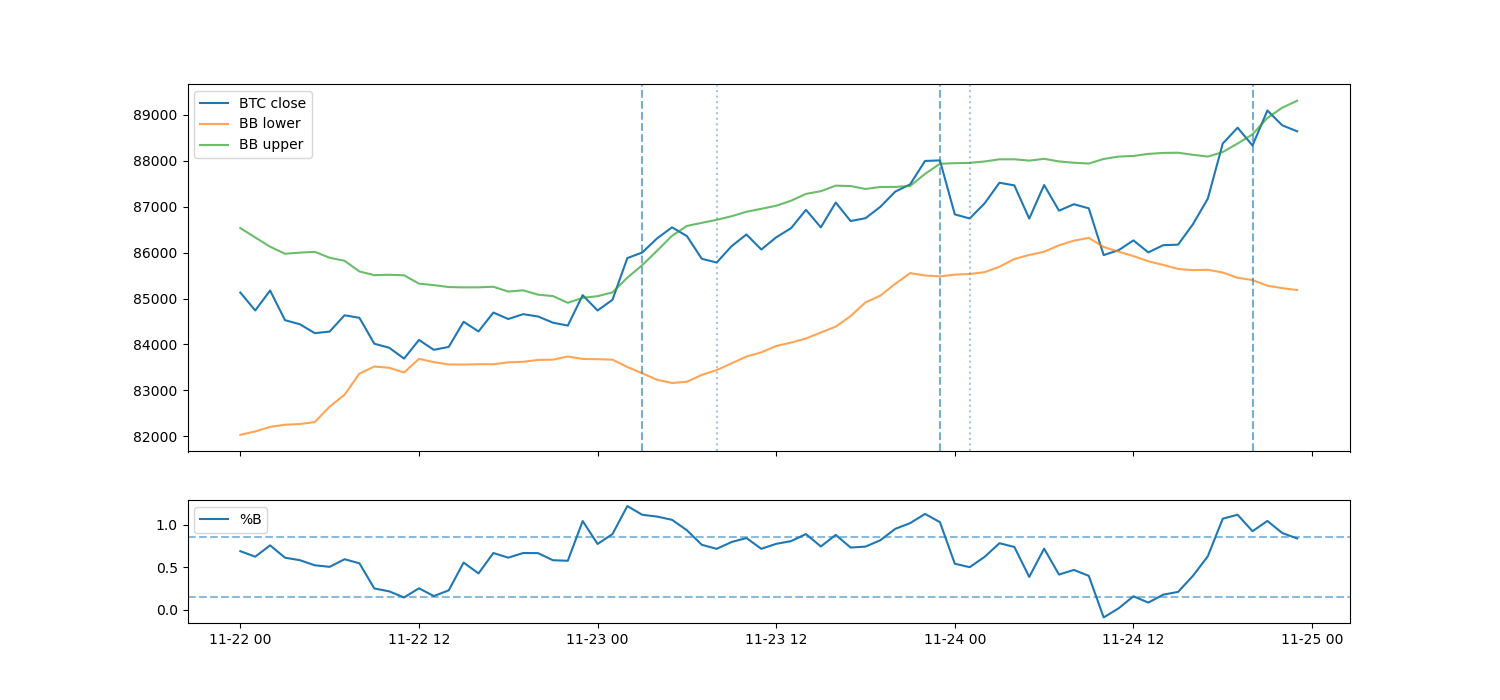

In [7]:
import matplotlib.pyplot as plt
%matplotlib widget
label='1H'; S='2025-11-22'; E='2025-11-24'
r=runs[label]; st=r['states'].loc[S:E]; tr=r['trace'].loc[S:E]
fig, (ax, bx)=plt.subplots(2,1,figsize=(15,7),sharex=True,
                          gridspec_kw={'height_ratios':[3,1]})
ax.plot(st.index,st['close'],label='BTC close')
ax.plot(st.index,st['bb_lower'],label='BB lower',alpha=.7)
ax.plot(st.index,st['bb_upper'],label='BB upper',alpha=.7)
for t in tr.index[tr.decision=='CONFIRMED']:ax.axvline(t,alpha=.6,ls='--')
for t in tr.index[tr.decision=='DISTANCE_EXIT']:ax.axvline(t,alpha=.4,ls=':')
ax.legend()
bx.plot(st.index,st['pct_b'],label='%B')
bx.axhline(CONFIG['near'],ls='--',alpha=.5)
bx.axhline(1-CONFIG['near'],ls='--',alpha=.5)
bx.legend();plt.show()

## Audit completion criteria

- Full-year traces generated for 4H, 1H, 15m and 5m.
- Every state and transition matches the frozen E0.2 baseline (asserted by code).
- Decision counters, candidate starts and exits are inspectable.
- Record input data coverage and Git commit hash before E0.3b.

**Not yet proved:** market truth labels, walk predictive performance, optimal thresholds, breakout likelihood given narrow band width, or calibrated false-alarm rates. Those require independent forward outcomes and proper chronological validation.